# 02 · Coleta e segmentação

O texto é o wikitext da revisão atual de cada artigo (`scripts/coleta.py`, `make coleta`). Ele é limpo e segmentado em sentenças por `scripts/sentencas.py` (`make sentencas`). A data de criação é estimada pelo pageid (`scripts/criacao.py`, `make criacao`). Este notebook só lê os resumos em `data/processed/`.

In [1]:
import sys; sys.path.insert(0, '../scripts')
import matplotlib.pyplot as plt
import pandas as pd
import analise_coleta as ac
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
F_COR, M_COR = '#b5367a', '#3b6fb6'
df = ac.carregar()
ac.cobertura(df)

,n
artigos,45397
ok,45383
ausentes,14
via redirecionamento,260
sem sentenças após limpeza,2


## Tamanho dos artigos por sexo

O tamanho é contado em palavras de prosa, depois da limpeza (sem infobox, tabelas, referências nem seções de lista).

,artigos,palavras (mediana),palavras (média),sentenças (mediana),palavras no lead (mediana),seções (mediana),% stubs (<150 palavras)
sexo,,,,,,,
F,9277,330.0,560.0,16.0,48.0,2.0,21.2
M,36106,303.0,522.0,15.0,45.0,2.0,25.7


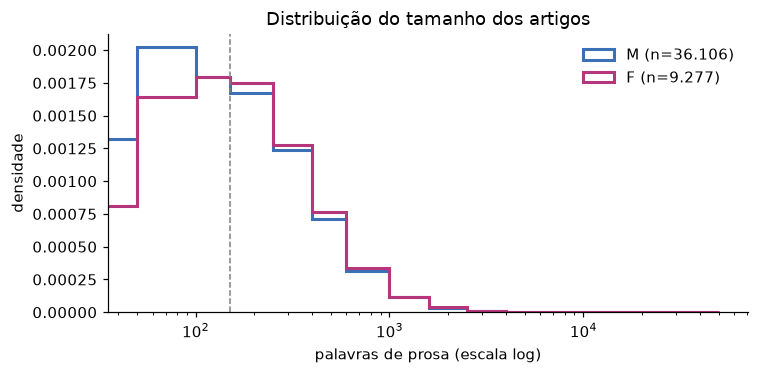

In [2]:
display(ac.tamanho_por_sexo(df))
ok = df[df.status == 'ok']
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = [0, 50, 100, 150, 250, 400, 600, 1000, 1600, 2500, 4000, 7000, 12000, 50000]
for s, c in [('M', M_COR), ('F', F_COR)]:
    v = ok[ok.sexo == s].palavras
    ax.hist(v.clip(upper=49999), bins=bins, histtype='step', lw=2, color=c, density=True, label=f'{s} (n={len(v):,})'.replace(',', '.'))
ax.set_xscale('log'); ax.axvline(ac.STUB, color='gray', ls='--', lw=1)
ax.set_xlabel('palavras de prosa (escala log)'); ax.set_ylabel('densidade'); ax.legend(frameon=False)
ax.set_title('Distribuição do tamanho dos artigos'); plt.tight_layout()

## Tamanho por área

In [3]:
ac.tamanho_por_area(df)

palavras (mediana)        % stubs       razão F/M
sexo                                    F      M       F     M   mediana
area                                                                    
outros                              363.0  429.0    21.9  18.4      0.85
musica                              460.5  378.0    12.9  18.2      1.22
literatura                          308.5  371.0    21.5  15.8      0.83
religiao                            489.0  370.0    10.0  11.9      1.32
jornalismo_comunicacao              330.0  345.5    14.0  15.7      0.96
esporte                             236.0  333.0    33.0  22.4      0.71
ciencia_academia                    392.5  327.0    13.7  24.7      1.20
artes_visuais                       374.0  320.0    17.7  21.2      1.17
atuacao_tv                          310.0  314.0    22.1  20.5      0.99
politica                            345.5  243.0    19.1  34.2      1.42
sem_ocupacao                        279.0  233.0    26.6  33.8      1.20

## Ano de criação do artigo (estimado)

A data é interpolada a partir do pageid, calibrada com uma amostra de primeiras revisões reais. O erro de calibração está em `data/processed/criacao_calibracao.csv` e é discutido no README.

sexo,F,M,total,%F
ano_criacao,,,,
2002.0,0,21,21,0.0
2003.0,11,48,59,18.6
2004.0,56,218,274,20.4
2005.0,268,1256,1524,17.6
2006.0,1133,4227,5360,21.1
2007.0,725,3949,4674,15.5
2008.0,514,4152,4666,11.0
2009.0,382,2806,3188,12.0
2010.0,373,2467,2840,13.1


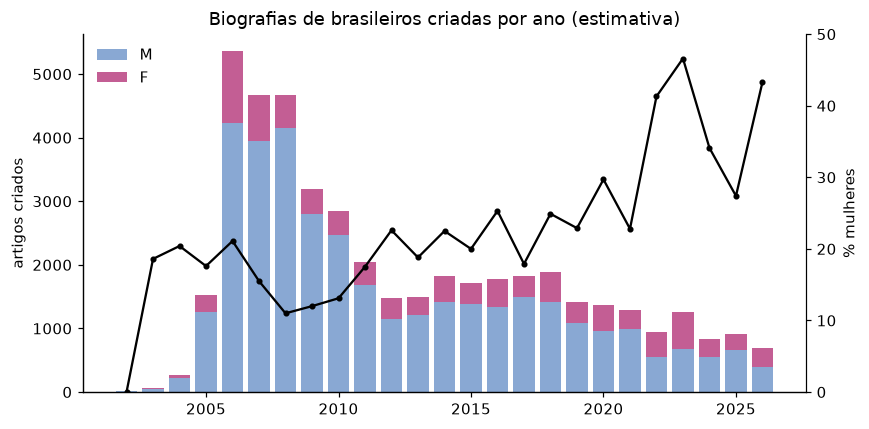

In [4]:
t = ac.pct_mulheres_por_ano_criacao(df)
if t is not None:
    display(t)
    fig, ax1 = plt.subplots(figsize=(8, 4))
    ax1.bar(t.index, t.M, color=M_COR, alpha=.6, label='M'); ax1.bar(t.index, t.F, bottom=t.M, color=F_COR, alpha=.8, label='F')
    ax1.set_ylabel('artigos criados'); ax1.legend(frameon=False, loc='upper left')
    ax2 = ax1.twinx(); ax2.plot(t.index, t['%F'], color='black', marker='o', ms=3); ax2.set_ylim(0, 50)
    ax2.set_ylabel('% mulheres'); ax2.spines['right'].set_visible(True)
    ax1.set_title('Biografias de brasileiros criadas por ano (estimativa)'); plt.tight_layout()

## Observações

- Os stubs (menos de 150 palavras de prosa) têm poucas sentenças, e as proporções calculadas neles são ruidosas. As análises devem ponderar ou estratificar por tamanho.
- Esporte tem artigos padronizados, com seções de carreira em clubes e de títulos. As seções de lista (títulos, estatísticas, discografia etc.) foram removidas.
- O texto vem da revisão atual (data em `rev_timestamp`). A pergunta 5 (tempo) usa o ano de criação do artigo, não a data da versão.